# 第 1 章配套 Notebook：线性代数最小集与脉冲线性可交换性伏笔

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch01_linear_algebra.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-01 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-01/notion/notebooks/ch01_linear_algebra.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 1 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 向量、矩阵与形状检查：`C_{ij} = sum_k A_{ik} B_{kj}`

复现第 1 章手算例 1.1：
$$A = \begin{bmatrix} 1 & 2 & -1 \\ 0 & 3 & 2 \end{bmatrix} \in \mathbb{R}^{2\times 3}, \quad B = \begin{bmatrix} 2 & 0 \\ -1 & 4 \\ 3 & 1 \end{bmatrix} \in \mathbb{R}^{3\times 2}$$

In [2]:
A = np.array([[1, 2, -1],
              [0, 3,  2]], dtype=float)
B = np.array([[ 2, 0],
              [-1, 4],
              [ 3, 1]], dtype=float)

print("A.shape =", A.shape, "(m=2, n=3)")
print("B.shape =", B.shape, "(n=3, p=2)")

# 手写三重循环逐元素按定义计算 C_{ij} = sum_{k=1}^n A_{ik} * B_{kj}
m, n = A.shape
n2, p = B.shape
assert n == n2, "内部维度必须相等才能相乘！"

C_manual = np.zeros((m, p), dtype=float)
for i in range(m):
    for j in range(p):
        terms = [f"({A[i,k]:.0f})*({B[k,j]:.0f})" for k in range(n)]
        C_manual[i, j] = sum(A[i, k] * B[k, j] for k in range(n))
        print(f"C[{i+1},{j+1}] = " + " + ".join(terms) + f" = {C_manual[i, j]:.0f}")

C_numpy = A @ B
assert np.allclose(C_manual, C_numpy)
assert np.allclose(C_numpy, np.array([[-3., 7.], [3., 14.]]))
print("\n最终矩阵 C = A @ B (shape =", C_numpy.shape, "):")
print(C_numpy)


A.shape = (2, 3) (m=2, n=3)
B.shape = (3, 2) (n=3, p=2)
C[1,1] = (1)*(2) + (2)*(-1) + (-1)*(3) = -3
C[1,2] = (1)*(0) + (2)*(4) + (-1)*(1) = 7
C[2,1] = (0)*(2) + (3)*(-1) + (2)*(3) = 3
C[2,2] = (0)*(0) + (3)*(4) + (2)*(1) = 14

最终矩阵 C = A @ B (shape = (2, 2) ):
[[-3.  7.]
 [ 3. 14.]]


## 2. 线性映射定义检验：$f(a\mathbf{x} + b\mathbf{y}) = a f(\mathbf{x}) + b f(\mathbf{y})$

对比三类映射：
1. 纯矩阵乘法 $f(\mathbf{x}) = W\mathbf{x}$（严格线性）；
2. 仿射映射 $g(\mathbf{x}) = W\mathbf{x} + \mathbf{b}$（当 $\mathbf{b}\neq \mathbf{0}$ 且 $a+b\neq 1$ 时不满足线性，但在权重之和为 1 的**时间平均**下满足 $g(\bar{\mathbf{x}}) = \frac{1}{T}\sum_t g(\mathbf{x}[t])$！）；
3. 非线性映射 $\mathrm{ReLU}(\mathbf{x}) = \max(0, \mathbf{x})$（不满足线性）。

In [3]:
W = np.array([[ 0.5, -0.2],
              [ 0.4,  0.8]], dtype=float)
b_vec = np.array([0.1, -0.3], dtype=float)

x = np.array([2.0, -1.0])
y = np.array([-1.0, 3.0])
a, b = 0.6, -0.5  # 注意 a + b = 0.1 != 1

# 1) 纯矩阵乘法 f(x) = Wx
lhs_linear = W @ (a * x + b * y)
rhs_linear = a * (W @ x) + b * (W @ y)
print("1) 纯矩阵乘 f(ax+by)      =", lhs_linear)
print("   af(x) + bf(y)         =", rhs_linear)
print("   误差范数              =", np.linalg.norm(lhs_linear - rhs_linear))
assert np.allclose(lhs_linear, rhs_linear)

# 2) 仿射映射 g(x) = Wx + b_vec 在一般线性组合下不相等，差值为 (1 - a - b) * b_vec
lhs_affine = W @ (a * x + b * y) + b_vec
rhs_affine = a * (W @ x + b_vec) + b * (W @ y + b_vec)
print("\n2) 仿射映射 g(ax+by)      =", lhs_affine)
print("   ag(x) + bg(y)         =", rhs_affine)
print("   差值 (等于 (1-a-b)*b) =", lhs_affine - rhs_affine, "理论值:", (1 - a - b) * b_vec)
assert np.allclose(lhs_affine - rhs_affine, (1 - a - b) * b_vec)

# 3) ReLU 非线性反例
lhs_relu = np.maximum(0.0, x + y)
rhs_relu = np.maximum(0.0, x) + np.maximum(0.0, y)
print("\n3) ReLU(x + y)           =", lhs_relu)
print("   ReLU(x) + ReLU(y)     =", rhs_relu)
print("   二者不相等！差值      =", lhs_relu - rhs_relu)


1) 纯矩阵乘 f(ax+by)      = [ 1.27 -1.  ]
   af(x) + bf(y)         = [ 1.27 -1.  ]
   误差范数              = 0.0

2) 仿射映射 g(ax+by)      = [ 1.37 -1.3 ]
   ag(x) + bg(y)         = [ 1.28 -1.03]
   差值 (等于 (1-a-b)*b) = [ 0.09 -0.27] 理论值: [ 0.09 -0.27]

3) ReLU(x + y)           = [1. 2.]
   ReLU(x) + ReLU(y)     = [2. 3.]
   二者不相等！差值      = [-1. -1.]


## 3. 埋下第 7 章伏笔：为什么“直接复制权重 $W$”对脉冲序列成立？

复现手算例 1.2：设 $T=4$ 个时间步，二值脉冲列 $\mathbf{s}[1..4] \in \{0,1\}^2$：
- 神经元 1 在 4 步里发了 3 次：`[1, 0, 1, 1]` $\implies$ 发放率 $r_1 = 0.75$；
- 神经元 2 在 4 步里发了 2 次：`[0, 1, 0, 1]` $\implies$ 发放率 $r_2 = 0.50$。

验证：**“先在每个时间步算脉冲加权和 $W\mathbf{s}[t]$ 再对时间求平均”** 与 **“先算出平均发放率 $\mathbf{r}$ 再乘一次 $W$”** 逐位严格相等！而如果把线性乘法换成逐元素取最大值，两者就会发生偏差。

In [4]:
# shape: (T=4, d_in=2)，每一行是一个时间步 t 的脉冲向量 s[t]
S = np.array([
    [1.0, 0.0],  # t = 1
    [0.0, 1.0],  # t = 2
    [1.0, 0.0],  # t = 3
    [1.0, 1.0],  # t = 4
])
T = S.shape[0]
r = S.mean(axis=0)  # 发放率向量 r = [0.75, 0.50]
print("发放率向量 r =", r)

# 脉冲网络做法：每一步只做加法（选出 s[t]=1 的列相加），最后求时间平均
step_outputs = np.array([W @ S[t] + b_vec for t in range(T)])
for t in range(T):
    print(f"  t={t+1}: s[{t+1}]={S[t]} -> W s[{t+1}] + b = {step_outputs[t]}")

avg_of_steps = step_outputs.mean(axis=0)
ann_on_rate  = W @ r + b_vec

print("\n逐步脉冲输出的时间平均 :", avg_of_steps)
print("直接把发放率喂给原权重 :", ann_on_rate)
assert np.allclose(avg_of_steps, ann_on_rate)
print("验证通过：最大绝对误差 =", np.max(np.abs(avg_of_steps - ann_on_rate)))


发放率向量 r = [0.75 0.5 ]
  t=1: s[1]=[1. 0.] -> W s[1] + b = [0.6 0.1]
  t=2: s[2]=[0. 1.] -> W s[2] + b = [-0.1  0.5]
  t=3: s[3]=[1. 0.] -> W s[3] + b = [0.6 0.1]
  t=4: s[4]=[1. 1.] -> W s[4] + b = [0.4 0.9]

逐步脉冲输出的时间平均 : [0.375 0.4  ]
直接把发放率喂给原权重 : [0.375 0.4  ]
验证通过：最大绝对误差 = 0.0


## 4. 练习配套实验区（改代码看现象：线性 vs 最大值不可交换）

你可以修改下面的脉冲序列 `S_exp`，观察线性矩阵乘误差始终为 0，而逐步 `max(s_1[t], s_2[t])` 的平均值高估了 `max(r_1, r_2)`。

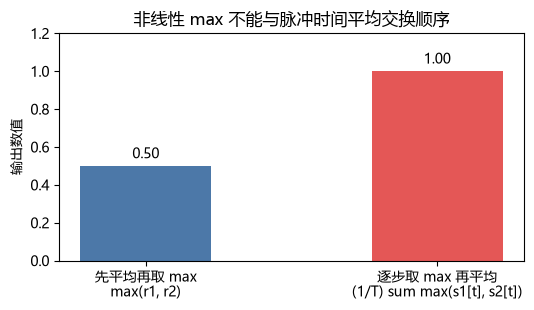

真实最大值 max(r1, r2) = 0.50, 逐步脉冲取最大均值 = 1.00（高估了 0.50）


In [5]:
S_exp = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [0.0, 1.0],
])
r_exp = S_exp.mean(axis=0)
max_of_mean = np.max(r_exp)                  # 先求发放率再取最大：max(0.5, 0.5) = 0.5
mean_of_max = np.mean(np.max(S_exp, axis=1)) # 每步先取最大再求平均：mean([1,1,1,1]) = 1.0

fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["先平均再取 max\nmax(r1, r2)", "逐步取 max 再平均\n(1/T) sum max(s1[t], s2[t])"],
              [max_of_mean, mean_of_max], color=["#4c78a8", "#e45756"], width=0.45)
ax.set_ylim(0, 1.2)
ax.set_ylabel("输出数值")
ax.set_title("非线性 max 不能与脉冲时间平均交换顺序")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.04, f"{bar.get_height():.2f}", ha="center")
plt.tight_layout()
plt.show()
print(f"真实最大值 max(r1, r2) = {max_of_mean:.2f}, 逐步脉冲取最大均值 = {mean_of_max:.2f}（高估了 {mean_of_max - max_of_mean:.2f}）")
